# Exploratory Data Analysis (EDA)

In [1]:

# CELL 1: Import necessary libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

# Create a folder to store EDA graphs and tables
OUTPUT = Path("eda_outputs")
OUTPUT.mkdir(exist_ok=True)

print("Libraries imported successfully!")
print("Output folder:", OUTPUT.resolve())


Libraries imported successfully!
Output folder: C:\Users\Pranjal\OneDrive\Desktop\Retail_Project\eda_outputs


In [2]:

# CELL 2: Read the cleaned datasets

transactions = pd.read_csv(
    "data/final_cleaned_transactions.csv",
    parse_dates=["InvoiceDate"]
)

invoices = pd.read_csv(
    "data/final_invoice_level.csv",
    parse_dates=["InvoiceDate"]
)

customers = pd.read_csv(
    "data/final_customer_level.csv"
)

print("Transaction data:", transactions.shape)
print("Invoice data:", invoices.shape)
print("Customer data:", customers.shape)


Transaction data: (802555, 14)
Invoice data: (36594, 13)
Customer data: (5852, 10)


In [3]:

# CELL 3: Inspect the datasets

print("TRANSACTION COLUMNS:")
print(transactions.columns.tolist())

print("\nINVOICE COLUMNS:")
print(invoices.columns.tolist())

print("\nCUSTOMER COLUMNS:")
print(customers.columns.tolist())

print("\nMISSING VALUES:")
print("Transactions:", transactions.isnull().sum().sum())
print("Invoices:", invoices.isnull().sum().sum())
print("Customers:", customers.isnull().sum().sum())

print("\nFIRST 5 INVOICES:")
display(invoices.head())


TRANSACTION COLUMNS:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'LineAmount', 'InvoiceYear', 'InvoiceMonth', 'PossibleExactDuplicate', 'DuplicateGroupSize', 'HighLineAmountFlag']

INVOICE COLUMNS:
['InvoiceYear', 'InvoiceNo', 'CustomerID', 'Country', 'InvoiceDate', 'InvoiceMonth', 'InvoiceAmount', 'ItemQuantity', 'ProductLineCount', 'DistinctProducts', 'PossibleDuplicateLineCount', 'HighInvoiceAmountFlag', 'InvoiceTimestampSpreadMinutes']

CUSTOMER COLUMNS:
['CustomerID', 'ObservedPurchaseCount', 'TotalSpending', 'AverageInvoiceValue', 'FirstObservedPurchase', 'LastObservedPurchase', 'ObservedCalendarSpanDays', 'DistinctCountries', 'HighInvoiceCount', 'InvoicesWithPossibleDuplicates']

MISSING VALUES:
Transactions: 0
Invoices: 0
Customers: 0

FIRST 5 INVOICES:


,InvoiceYear,InvoiceNo,CustomerID,Country,InvoiceDate,InvoiceMonth,InvoiceAmount,ItemQuantity,ProductLineCount,DistinctProducts,PossibleDuplicateLineCount,HighInvoiceAmountFlag,InvoiceTimestampSpreadMinutes
0,2009,489434,13085,United Kingdom,2009-12-01 07:45:00,2009-12,505.30,166,8,8,0,False,0.0
1,2009,489435,13085,United Kingdom,2009-12-01 07:46:00,2009-12,145.80,60,4,4,0,False,0.0
2,2009,489436,13078,United Kingdom,2009-12-01 09:06:00,2009-12,630.33,193,19,19,0,False,0.0
3,2009,489437,15362,United Kingdom,2009-12-01 09:08:00,2009-12,310.75,145,23,23,0,False,0.0
4,2009,489438,18102,United Kingdom,2009-12-01 09:24:00,2009-12,2286.24,826,17,17,0,False,0.0


In [4]:

# CELL 4: Descriptive statistics

variables = {
    "Product Quantity": transactions["Quantity"],
    "Line Amount": transactions["LineAmount"],
    "Invoice Amount": invoices["InvoiceAmount"],
    "Purchase Count": customers["ObservedPurchaseCount"],
    "Customer Total Spending": customers["TotalSpending"]
}

summary = pd.DataFrame()

for name, data in variables.items():
    summary.loc[name, "Count"] = data.count()
    summary.loc[name, "Mean"] = data.mean()
    summary.loc[name, "Median"] = data.median()
    summary.loc[name, "Variance"] = data.var()
    summary.loc[name, "Std Dev"] = data.std()
    summary.loc[name, "Skewness"] = data.skew()
    summary.loc[name, "Kurtosis"] = data.kurt()
    summary.loc[name, "Minimum"] = data.min()
    summary.loc[name, "Maximum"] = data.max()

display(summary.round(2))

summary.to_csv(OUTPUT / "descriptive_statistics.csv")


,Count,Mean,Median,Variance,Std Dev,Skewness,Kurtosis,Minimum,Maximum
Product Quantity,802555.0,13.32,5.00,2.070025e+04,143.88,405.88,214216.17,1.00,80995.00
Line Amount,802555.0,21.72,11.80,4.954274e+04,222.58,599.92,427932.10,0.06,168469.60
Invoice Amount,36594.0,476.40,304.64,1.888534e+06,1374.24,60.27,6469.43,0.38,168469.60
Purchase Count,5852.0,6.25,3.00,1.625400e+02,12.75,12.04,240.20,1.00,373.00
Customer Total Spending,5852.0,2979.03,880.38,2.133049e+08,14604.96,25.58,871.50,2.95,608821.65


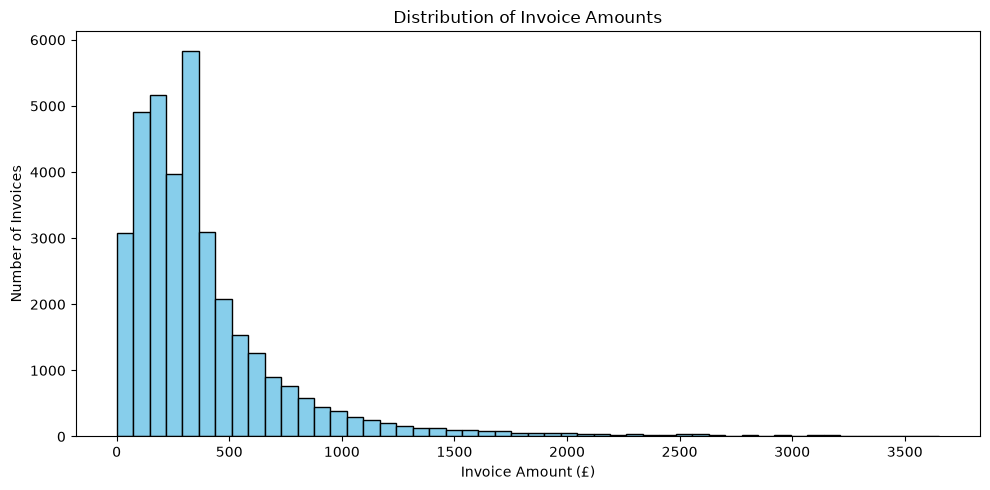

In [5]:

# CELL 5: Distribution of invoice amounts

amounts = invoices["InvoiceAmount"]

# Show values up to the 99th percentile
limit = amounts.quantile(0.99)
plot_data = amounts[amounts <= limit]

plt.figure(figsize=(10, 5))

plt.hist(
    plot_data,
    bins=50,
    color="skyblue",
    edgecolor="black"
)

plt.title("Distribution of Invoice Amounts")
plt.xlabel("Invoice Amount (£)")
plt.ylabel("Number of Invoices")

plt.tight_layout()
plt.savefig(
    OUTPUT / "invoice_amount_histogram.png",
    dpi=300
)
plt.show()


**Distribution of Invoice Amounts (Histogram)**


The histogram shows a highly positively skewed distribution of invoice amounts, with most transactions concentrated in the lower spending range and relatively fewer high-value transactions. The mean invoice amount (£476.40) exceeds the median (£304.64), further indicating right-skewness. This suggests considerable variability in customer spending behaviour. The observed pattern motivates the application of the Gamma distribution to model positive transaction amounts, subject to goodness-of-fit evaluation.

C:\Users\Pranjal\AppData\Local\Temp\ipykernel_9920\693429518.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


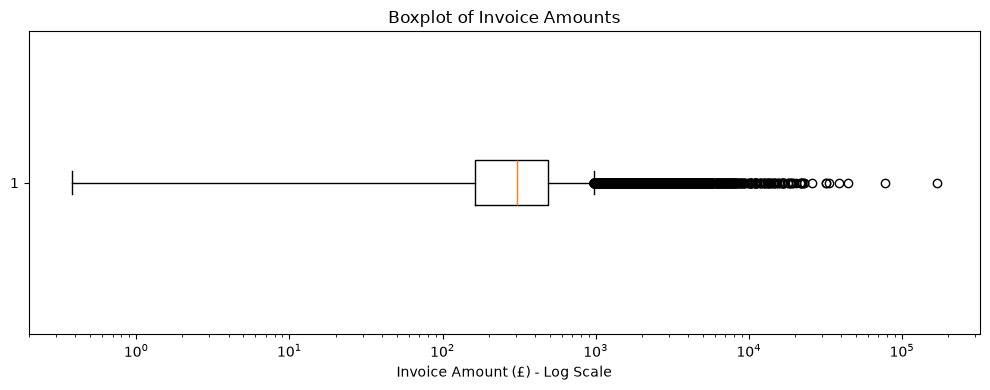

In [6]:

# CELL 6: Boxplot of invoice amounts

plt.figure(figsize=(10, 4))

plt.boxplot(
    invoices["InvoiceAmount"],
    vert=False
)

# Log scale helps show a wide range of values
plt.xscale("log")

plt.title("Boxplot of Invoice Amounts")
plt.xlabel("Invoice Amount (£) - Log Scale")

plt.tight_layout()
plt.savefig(
    OUTPUT / "invoice_amount_boxplot.png",
    dpi=300
)
plt.show()


**Boxplot of Invoice Amounts**

The boxplot reveals substantial variation in invoice amounts, with numerous observations extending beyond the upper whisker. These high-value transactions indicate that a relatively small proportion of purchases involve considerably larger spending amounts. The presence of extreme values contributes to the positive skewness of the distribution. Since these transactions may represent genuine bulk purchases, they should not be removed without justification. This highlights the importance of selecting a probability distribution capable of representing right-skewed spending behaviour.

Mean purchase count: 6.25
Variance: 162.54
Variance-to-Mean Ratio: 25.99


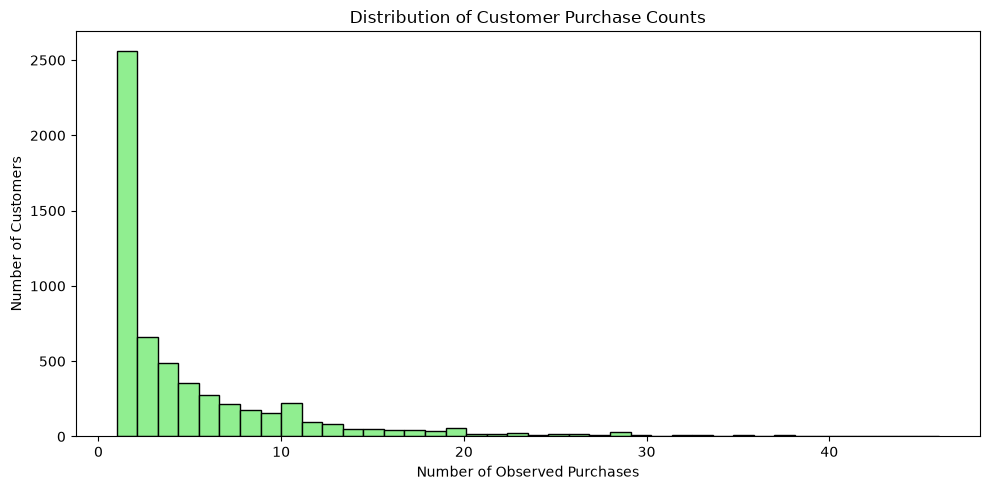

In [7]:

# CELL 7: Purchase count analysis

purchase_counts = customers["ObservedPurchaseCount"]

mean_count = purchase_counts.mean()
variance_count = purchase_counts.var()

dispersion_ratio = variance_count / mean_count

print("Mean purchase count:", round(mean_count, 2))
print("Variance:", round(variance_count, 2))
print("Variance-to-Mean Ratio:", round(dispersion_ratio, 2))

# Histogram
plt.figure(figsize=(10, 5))

plt.hist(
    purchase_counts[
        purchase_counts <= purchase_counts.quantile(0.99)
    ],
    bins=40,
    color="lightgreen",
    edgecolor="black"
)

plt.title("Distribution of Customer Purchase Counts")
plt.xlabel("Number of Observed Purchases")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.savefig(
    OUTPUT / "customer_purchase_count.png",
    dpi=300
)
plt.show()


**Distribution of Customer Purchase Frequency (Histogram)**

The histogram indicates a strongly right-skewed distribution of observed customer purchase counts. Most customers make relatively few purchases, while a smaller group purchases frequently. The mean purchase count is approximately 6.25, with a variance of 162.54, indicating substantial overdispersion. This suggests that customers exhibit heterogeneous purchasing behaviour and that a single Poisson distribution may not adequately capture the observed variability. The findings motivate further investigation using finite mixture models.

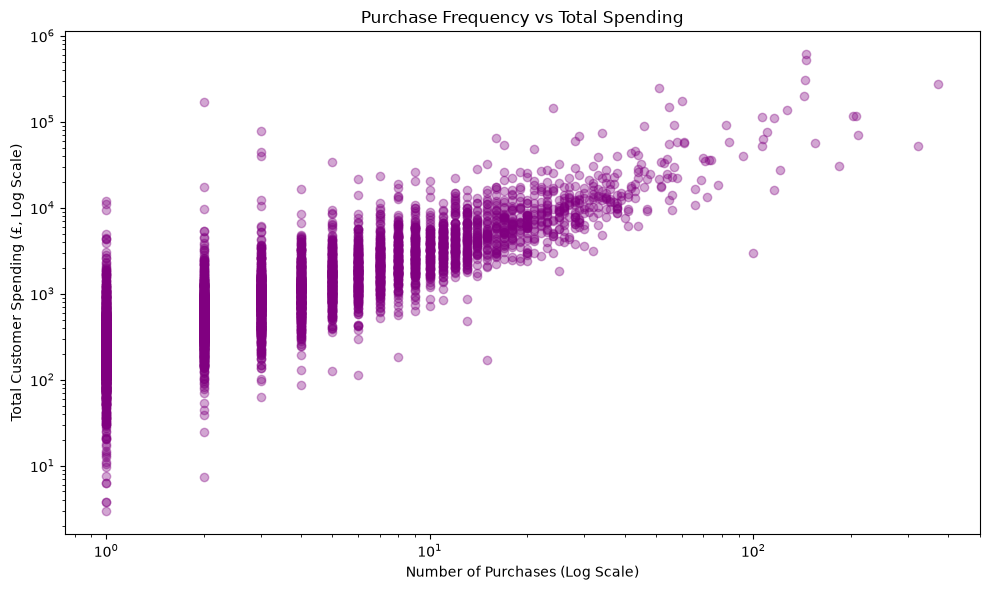

In [8]:

# CELL 8: Purchase count vs spending

plt.figure(figsize=(10, 6))

plt.scatter(
    customers["ObservedPurchaseCount"],
    customers["TotalSpending"],
    alpha=0.35,
    color="purple"
)

plt.xscale("log")
plt.yscale("log")

plt.title("Purchase Frequency vs Total Spending")
plt.xlabel("Number of Purchases (Log Scale)")
plt.ylabel("Total Customer Spending (£, Log Scale)")

plt.tight_layout()
plt.savefig(
    OUTPUT / "frequency_vs_spending.png",
    dpi=300
)
plt.show()


**Purchase Frequency vs Total Customer Spending (Scatter Plot)**

The scatter plot demonstrates a generally positive association between purchase frequency and total customer spending. Customers who purchase more frequently tend to generate higher total spending. However, considerable variability exists, as customers with similar purchase frequencies may have different spending amounts. This indicates that purchase frequency alone does not completely explain spending behaviour. The observed heterogeneity supports investigating finite mixture models for customer segmentation and incorporating both purchasing frequency and transaction value into Customer Lifetime Value (CLV) modelling.

Number of months: 25


InvoiceMonth
2009-12    681066.22
2010-01    535229.37
2010-02    499749.68
2010-03    668577.19
2010-04    587753.77
Name: InvoiceAmount, dtype: float64

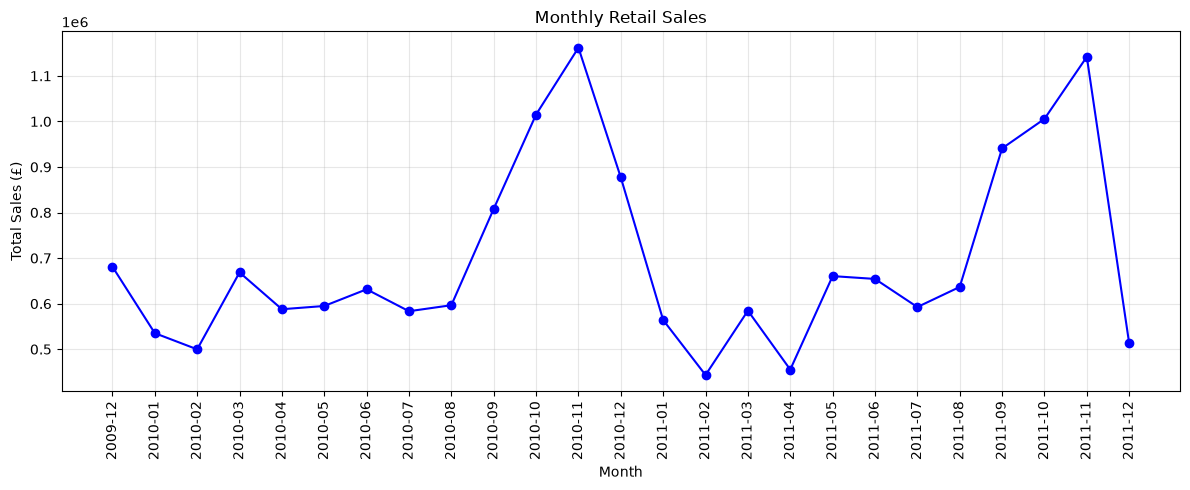

In [9]:

# CELL 9: Monthly sales analysis

monthly_sales = (
    invoices.groupby("InvoiceMonth")["InvoiceAmount"]
    .sum()
)

print("Number of months:", len(monthly_sales))

display(monthly_sales.head())

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    color="blue"
)

plt.title("Monthly Retail Sales")
plt.xlabel("Month")
plt.ylabel("Total Sales (£)")

plt.xticks(rotation=90)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT / "monthly_sales.png",
    dpi=300
)
plt.show()


**Monthly Sales Trend (Line Graph)**

The monthly sales graph reveals noticeable fluctuations in total revenue across the observation period. Sales increase considerably during the later months of both 2010 and 2011, with particularly high values toward the year-end shopping periods. This suggests the possibility of seasonal purchasing patterns. However, further analysis is required to establish seasonality, and incomplete boundary months should be interpreted cautiously. These fluctuations highlight the importance of accounting for time-related changes when modelling customer spending and simulating future revenue.

InvoiceMonth
2009-12    1497
2010-01     959
2010-02    1093
2010-03    1509
2010-04    1315
Name: InvoiceNo, dtype: int64


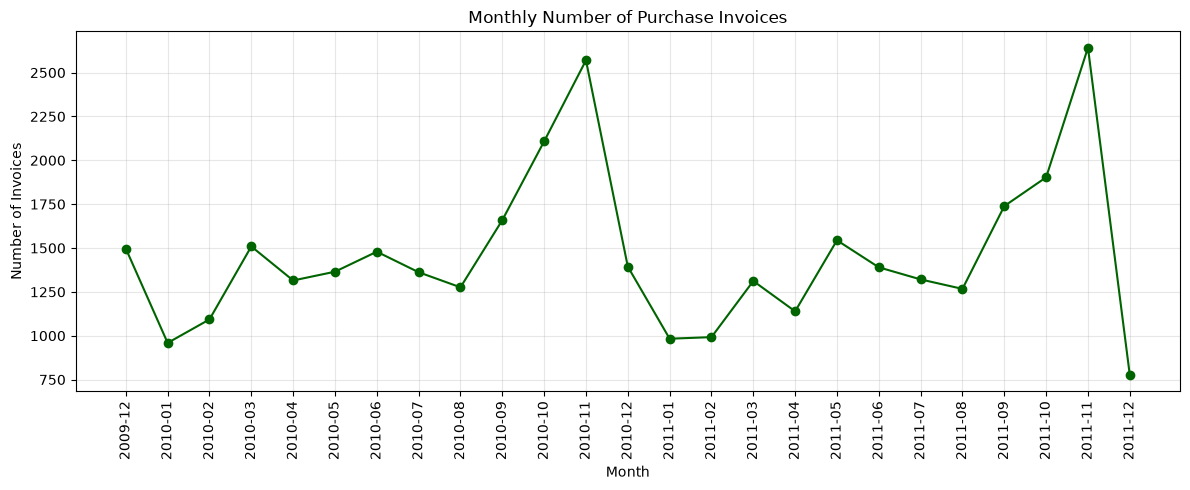

In [10]:

# CELL 10: Monthly invoice counts

monthly_orders = (
    invoices.groupby("InvoiceMonth")["InvoiceNo"]
    .count()
)

print(monthly_orders.head())

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_orders.index,
    monthly_orders.values,
    marker="o",
    color="darkgreen"
)

plt.title("Monthly Number of Purchase Invoices")
plt.xlabel("Month")
plt.ylabel("Number of Invoices")

plt.xticks(rotation=90)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT / "monthly_invoice_counts.png",
    dpi=300
)
plt.show()


**Monthly Number of Purchase Invoices (Line Graph)**

The graph illustrates variations in the number of purchase invoices recorded each month. Purchasing activity rises during the later months of 2010 and 2011, broadly corresponding to the periods of higher sales observed in the previous graph. This suggests that changes in total revenue are partly associated with changes in purchasing frequency. The monthly variation also indicates that customer purchasing activity may not remain constant over time, an important consideration when applying the Poisson distribution to purchase counts.

Number of observed intervals: 30742
count    30742.00
mean        52.12
std         75.90
min          0.00
25%          7.02
50%         25.03
75%         62.08
max        714.15
Name: WaitingDays, dtype: float64


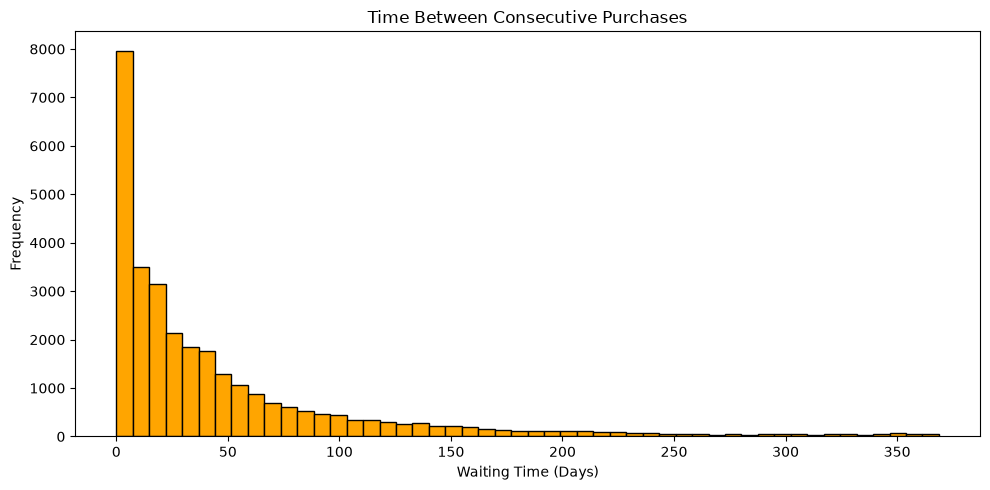

In [11]:

# CELL 11: Interpurchase waiting times

sorted_invoices = invoices.sort_values(
    ["CustomerID", "InvoiceDate"]
).copy()

# Calculate time between consecutive invoices
sorted_invoices["WaitingDays"] = (
    sorted_invoices.groupby("CustomerID")["InvoiceDate"]
    .diff()
    .dt.total_seconds() / 86400
)

waiting = sorted_invoices["WaitingDays"].dropna()

print("Number of observed intervals:", len(waiting))
print(waiting.describe().round(2))

plt.figure(figsize=(10, 5))

plt.hist(
    waiting[waiting <= waiting.quantile(0.99)],
    bins=50,
    color="orange",
    edgecolor="black"
)

plt.title("Time Between Consecutive Purchases")
plt.xlabel("Waiting Time (Days)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig(
    OUTPUT / "interpurchase_waiting_times.png",
    dpi=300
)
plt.show()


**Time Between Consecutive Purchases (Histogram)**

The histogram of interpurchase waiting times displays a positively skewed distribution, with a high concentration of shorter waiting intervals and progressively fewer longer intervals. This indicates that many repeat purchases occur within relatively short periods, while some customers return only after considerably longer gaps. The pattern suggests substantial variation in repeat-purchasing behaviour. This analysis provides a foundation for studying waiting-time distributions, although the suitability of a Geometric distribution depends on defining discrete purchase opportunities and evaluating its assumptions.

Number of countries: 41


Country
United Kingdom    14620858.20
EIRE                591536.65
Netherlands         549952.66
Germany             388829.75
France              315261.67
Australia           168484.66
Spain                98612.79
Switzerland          93624.34
Sweden               86079.04
Denmark              68560.19
Name: LineAmount, dtype: float64

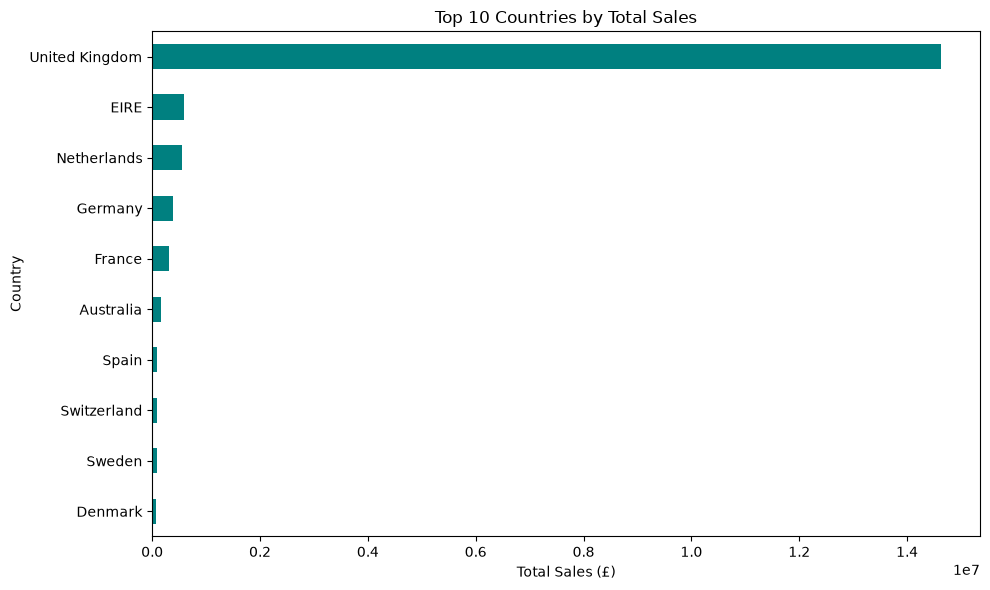

In [12]:

# CELL 12: Country-wise total sales

country_sales = (
    transactions.groupby("Country")["LineAmount"]
    .sum()
    .sort_values(ascending=False)
)

top_countries = country_sales.head(10)

print("Number of countries:", len(country_sales))

display(top_countries)

plt.figure(figsize=(10, 6))

top_countries.sort_values().plot(
    kind="barh",
    color="teal"
)

plt.title("Top 10 Countries by Total Sales")
plt.xlabel("Total Sales (£)")
plt.ylabel("Country")

plt.tight_layout()
plt.savefig(
    OUTPUT / "top_countries.png",
    dpi=300
)
plt.show()


**Top 10 Countries by Total Sales (Horizontal Bar Chart)**

The country-wise sales comparison shows that the United Kingdom contributes the overwhelming majority of recorded sales, while countries such as EIRE (Ireland), the Netherlands, Germany, and France account for much smaller shares. This indicates a substantial geographical concentration in the dataset. Consequently, the overall purchasing patterns are likely to be strongly influenced by UK transactions. This geographical imbalance should be considered when interpreting distribution-fitting results and generalizing conclusions to customers from other countries.

In [13]:

# CELL 13: Final EDA summary

eda_summary = pd.DataFrame({
    "Metric": [
        "Total Product Lines",
        "Total Invoices",
        "Total Customers",
        "Total Recorded Sales (£)",
        "Mean Invoice Amount (£)",
        "Median Invoice Amount (£)",
        "Mean Observed Purchase Count",
        "Purchase Count Variance",
        "Mean Customer Spending (£)",
        "Number of Countries"
    ],
    "Value": [
        len(transactions),
        len(invoices),
        len(customers),
        transactions["LineAmount"].sum(),
        invoices["InvoiceAmount"].mean(),
        invoices["InvoiceAmount"].median(),
        customers["ObservedPurchaseCount"].mean(),
        customers["ObservedPurchaseCount"].var(),
        customers["TotalSpending"].mean(),
        transactions["Country"].nunique()
    ]
})

display(eda_summary.round(2))

eda_summary.to_csv(
    OUTPUT / "final_eda_summary.csv",
    index=False
)

print("EDA summary saved successfully!")


,Metric,Value
0,Total Product Lines,802555.00
1,Total Invoices,36594.00
2,Total Customers,5852.00
3,Total Recorded Sales (£),17433264.73
4,Mean Invoice Amount (£),476.40
5,Median Invoice Amount (£),304.64
6,Mean Observed Purchase Count,6.25
7,Purchase Count Variance,162.54
8,Mean Customer Spending (£),2979.03
9,Number of Countries,41.00


EDA summary saved successfully!
